In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np

In [2]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0, 
     21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5, 
     22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5, 
     27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0, 
     36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0, 
     40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
     )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0, 
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0, 
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0, 
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0, 
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 
     1000.0, 1000.0]
     )

In [3]:

# 훈련데이터, 테스트데이터 분류
train_data, test_data, train_label, test_label = train_test_split(
perch_length, perch_weight, random_state=42)  # 회귀 : stratify 사용하지 않음

# sklearn은 2차원 배열을 사용, 그래서 훈련데이터, 테스트데이터를 2차원 배열로 변경
train_data = train_data.reshape(-1, 1)  # 1차원을 2차원 형태로 변경 - 2차원으로 입력이 되어야 함.
test_data = test_data.reshape(-1, 1)


In [5]:
# 선형 회귀모델 적용시 
lr = LinearRegression()              #  데이터 밖의 예측도 근사치로 예측이 됨.
# knr = KNeighborsRegressor() # knn알고리즘을 사용할때 데이터 밖의 예측은 제대로 되지 않음
lr.fit(train_data, train_label)
fish_length = 50 # 농어 50cm
fish_length2 = 100 # 농어 100cm
predict = lr.predict([[fish_length]])   
print("예측무게1 : ",predict)     # 1241.8386… 
predict2 = lr.predict([[fish_length2]])  
print("예측무게2 : ",predict2)

예측무게1 :  [1241.83860323]
예측무게2 :  [3192.69585141]


In [7]:
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print('학습데이터 예측 : ',score)
print('테스트데이터 예측 : ',score2)

학습데이터 예측 :  0.9398463339976041
테스트데이터 예측 :  0.824750312331356


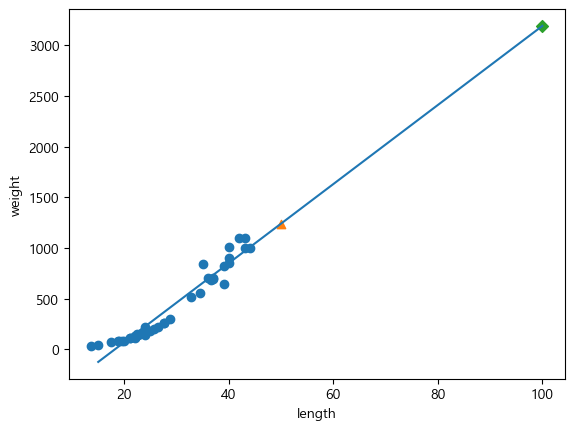

In [6]:
# 산점도 그래프
plt.scatter(train_data, train_label)
plt.scatter(fish_length, predict, marker='^')
plt.scatter(fish_length2, predict2, marker='D')
# 직선 그래프 15에서 50
plt.plot([15,100],[15*lr.coef_+lr.intercept_,100*lr.coef_+lr.intercept_])
plt.xlabel('length')
plt.ylabel('weight')
plt.show()